<a href="https://colab.research.google.com/github/SUSHMITHA193/Internship-on-Data-Science/blob/main/Week2_Advanced_Weather_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from google.colab import files
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

# Upload your original weather.csv
uploaded = files.upload()

df = pd.read_csv("weather_cleaned.csv")
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())


Saving weather_cleaned.csv to weather_cleaned (1).csv
Dataset shape: (366, 22)
Columns: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'WindDir9am', 'WindDir3pm', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'RISK_MM', 'RainTomorrow']


,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RISK_MM,RainTomorrow
0,8.0,24.3,0.0,3.4,6.3,NW,30.0,SW,NW,6.0,...,29,1019.7,1015.0,7,7,14.4,23.6,No,3.6,Yes
1,14.0,26.9,3.6,4.4,9.7,ENE,39.0,E,W,4.0,...,36,1012.4,1008.4,5,3,17.5,25.7,Yes,3.6,Yes
2,13.7,23.4,3.6,5.8,3.3,NW,85.0,N,NNE,6.0,...,69,1009.5,1007.2,8,7,15.4,20.2,Yes,39.8,Yes
3,13.3,15.5,39.8,7.2,9.1,NW,54.0,WNW,W,30.0,...,56,1005.5,1007.0,2,7,13.5,14.1,Yes,2.8,Yes
4,7.6,16.1,2.8,5.6,10.6,SSE,50.0,SSE,ESE,20.0,...,49,1018.3,1018.5,7,7,11.1,15.4,Yes,0.0,No


In [4]:

# Create a separate analysis copy
data = df.copy()

# Convert available numeric columns to numeric types
numeric_columns = [
    "MinTemp", "MaxTemp", "Rainfall", "Evaporation",
    "Sunshine", "WindGustSpeed", "WindSpeed9am",
    "WindSpeed3pm", "Humidity9am", "Humidity3pm",
    "Pressure9am", "Pressure3pm", "Cloud9am", "Cloud3pm",
    "Temp9am", "Temp3pm"
]

for col in numeric_columns:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Parse date if the dataset contains a Date column
if "Date" in data.columns:
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")

# Show missing values before chart-specific handling
print("Missing values:")
display(data.isnull().sum().sort_values(ascending=False).head(15))

print("Duplicate rows:", data.duplicated().sum())


Missing values:


,0
MinTemp,0
MaxTemp,0
Rainfall,0
Evaporation,0
Sunshine,0
WindGustDir,0
WindGustSpeed,0
WindDir9am,0
WindDir3pm,0
WindSpeed9am,0


Duplicate rows: 0


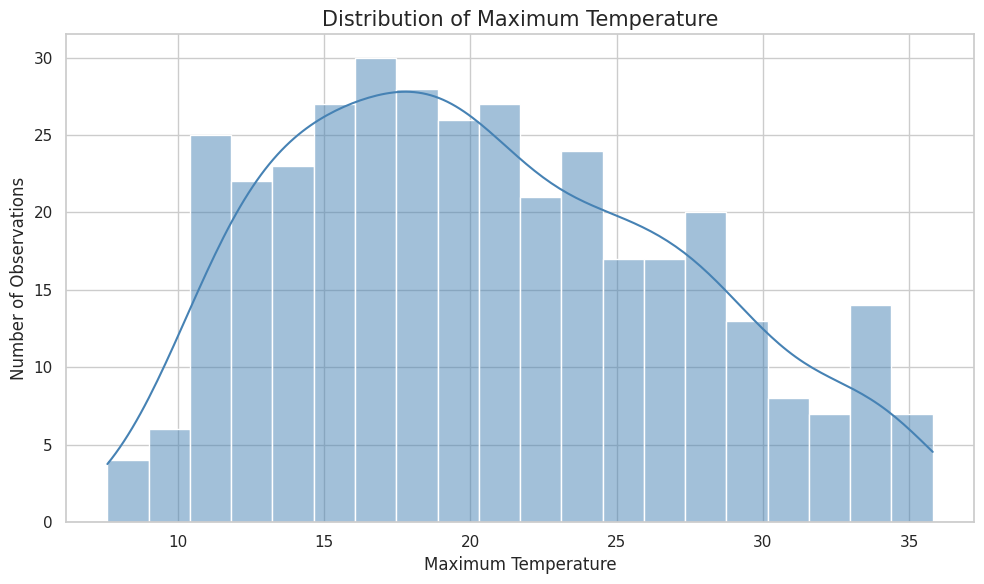

In [5]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=data,
    x="MaxTemp",
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Maximum Temperature", fontsize=15)
plt.xlabel("Maximum Temperature")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.savefig("01_temperature_distribution.png", dpi=300)
plt.show()


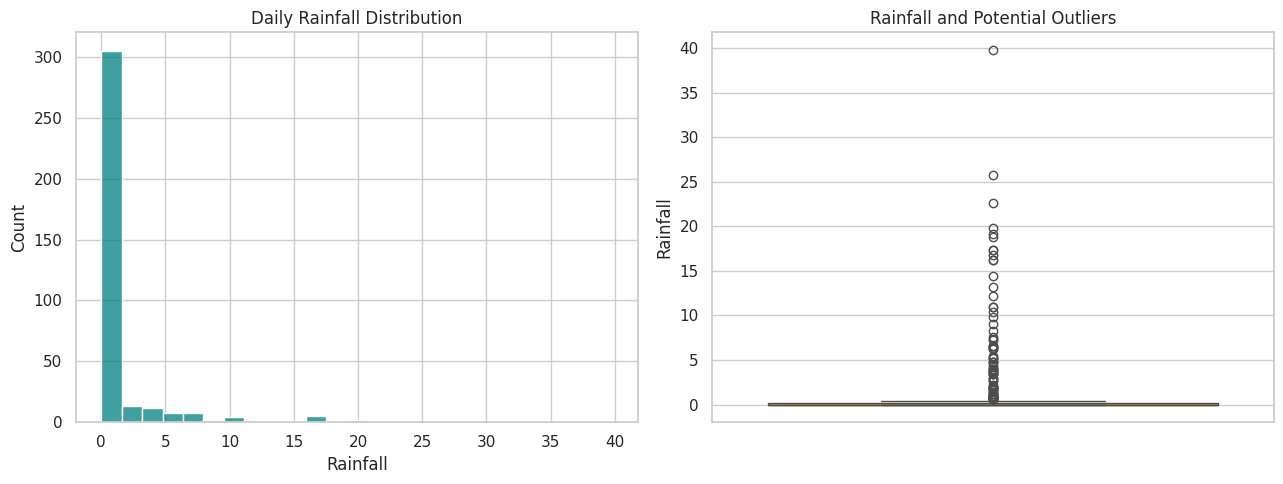

count    366.000000
mean       1.428415
std        4.225800
min        0.000000
25%        0.000000
50%        0.000000
75%        0.200000
max       39.800000
Name: Rainfall, dtype: float64


In [6]:

rain_data = data.dropna(subset=["Rainfall"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    data=rain_data,
    x="Rainfall",
    bins=25,
    ax=axes[0],
    color="teal"
)
axes[0].set_title("Daily Rainfall Distribution")
axes[0].set_xlabel("Rainfall")

sns.boxplot(
    data=rain_data,
    y="Rainfall",
    ax=axes[1],
    color="orange"
)
axes[1].set_title("Rainfall and Potential Outliers")
axes[1].set_ylabel("Rainfall")

plt.tight_layout()
plt.savefig("02_rainfall_distribution_outliers.png", dpi=300)
plt.show()

print(rain_data["Rainfall"].describe())


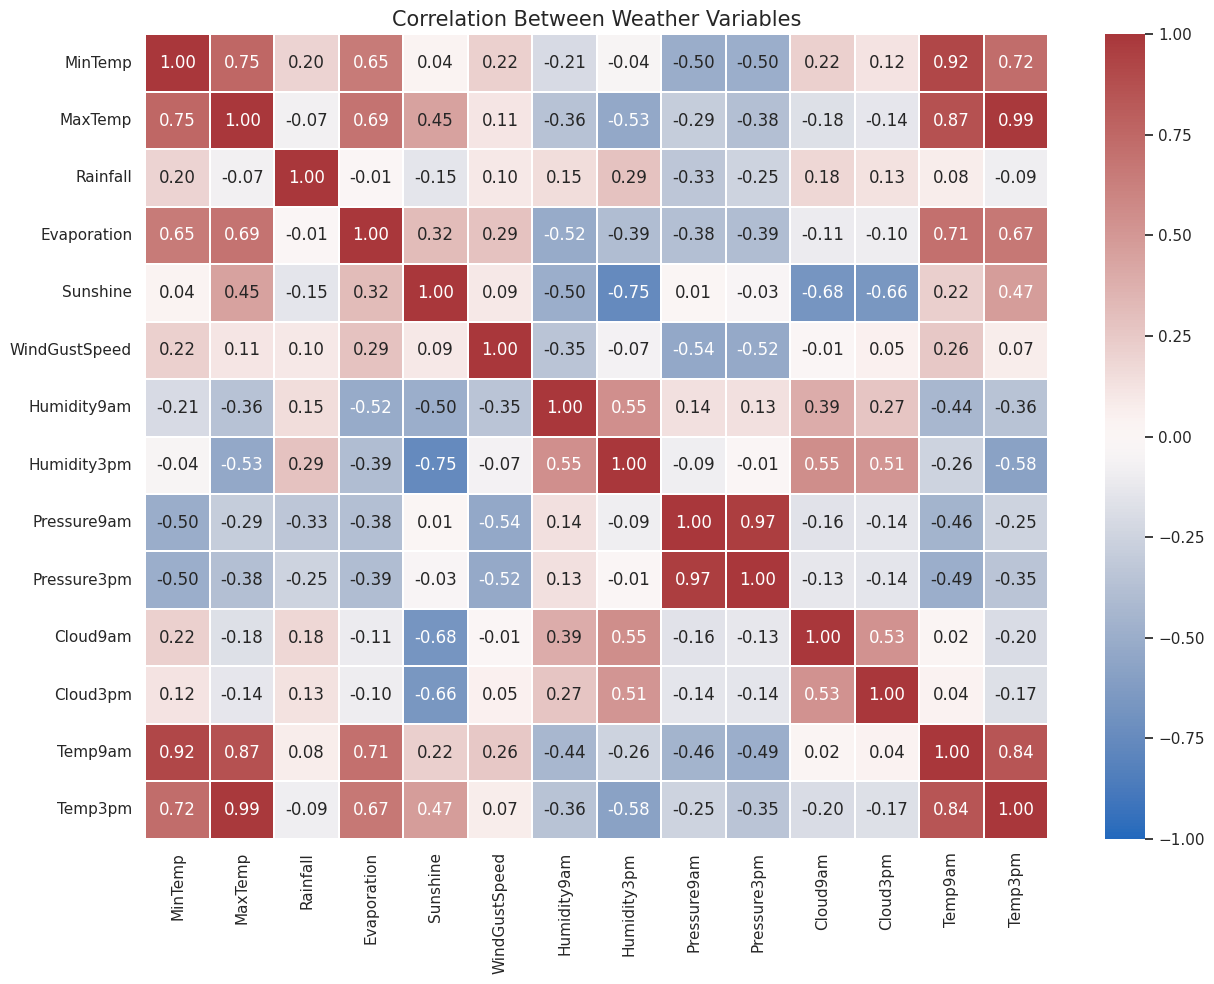

In [7]:

corr_cols = [
    "MinTemp", "MaxTemp", "Rainfall", "Evaporation",
    "Sunshine", "WindGustSpeed", "Humidity9am",
    "Humidity3pm", "Pressure9am", "Pressure3pm",
    "Cloud9am", "Cloud3pm", "Temp9am", "Temp3pm"
]

corr_cols = [c for c in corr_cols if c in data.columns]

corr_data = data[corr_cols].apply(pd.to_numeric, errors="coerce")
corr_matrix = corr_data.corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    corr_matrix,
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.3
)

plt.title("Correlation Between Weather Variables", fontsize=15)
plt.tight_layout()
plt.savefig("03_weather_correlation_heatmap.png", dpi=300)
plt.show()


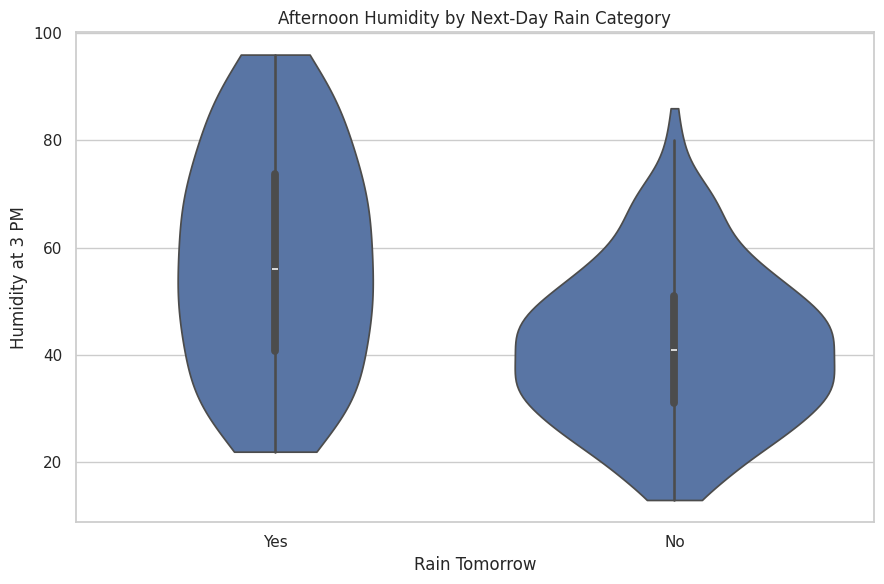

,count,median,mean,std
RainTomorrow,,,,
No,300,41.0,41.62,14.49
Yes,66,56.0,57.68,20.36


In [8]:

if {"RainTomorrow", "Humidity3pm"}.issubset(data.columns):
    plot_data = data.dropna(
        subset=["RainTomorrow", "Humidity3pm"]
    ).copy()

    plt.figure(figsize=(9, 6))

    sns.violinplot(
        data=plot_data,
        x="RainTomorrow",
        y="Humidity3pm",
        inner="box",
        cut=0
    )

    plt.title("Afternoon Humidity by Next-Day Rain Category")
    plt.xlabel("Rain Tomorrow")
    plt.ylabel("Humidity at 3 PM")
    plt.tight_layout()
    plt.savefig("04_humidity_rain_comparison.png", dpi=300)
    plt.show()

    display(
        plot_data.groupby("RainTomorrow")["Humidity3pm"]
        .agg(["count", "median", "mean", "std"])
        .round(2)
    )
else:
    print("Required columns are not available.")


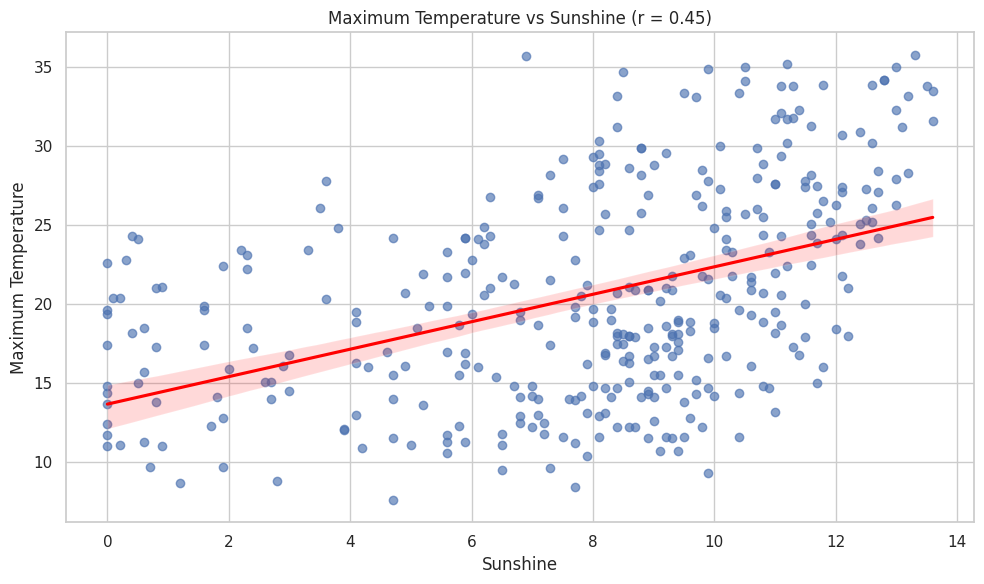

Pearson correlation: 0.451


In [9]:

if {"MaxTemp", "Sunshine"}.issubset(data.columns):
    plot_data = data.dropna(subset=["MaxTemp", "Sunshine"])

    plt.figure(figsize=(10, 6))

    sns.regplot(
        data=plot_data,
        x="Sunshine",
        y="MaxTemp",
        scatter_kws={"alpha": 0.65},
        line_kws={"color": "red"}
    )

    correlation = plot_data["Sunshine"].corr(
        plot_data["MaxTemp"]
    )

    plt.title(
        f"Maximum Temperature vs Sunshine (r = {correlation:.2f})"
    )
    plt.xlabel("Sunshine")
    plt.ylabel("Maximum Temperature")
    plt.tight_layout()
    plt.savefig("05_temperature_sunshine_relationship.png", dpi=300)
    plt.show()

    print("Pearson correlation:", round(correlation, 3))


In [10]:

if {"MaxTemp", "Humidity3pm", "RainTomorrow"}.issubset(data.columns):
    plot_data = data.dropna(
        subset=["MaxTemp", "Humidity3pm", "RainTomorrow"]
    ).copy()

    fig = px.scatter(
        plot_data,
        x="MaxTemp",
        y="Humidity3pm",
        color="RainTomorrow",
        hover_data=[
            c for c in ["Date", "Rainfall", "Sunshine"]
            if c in plot_data.columns
        ],
        title="Interactive Weather Explorer",
        labels={
            "MaxTemp": "Maximum Temperature",
            "Humidity3pm": "Humidity at 3 PM",
            "RainTomorrow": "Rain Tomorrow"
        },
        template="plotly_white"
    )

    fig.show()
    fig.write_html("06_interactive_weather_explorer.html")
else:
    print("Required columns are not available.")
